In [1]:
from google.colab import files
from pathlib import Path
import zipfile, io, sys

uploaded = files.upload()  # choose the course ZIP or Debiasing.zip
name = next(k for k in uploaded if k.lower().endswith('.zip'))
archive = zipfile.ZipFile(io.BytesIO(uploaded[name]))
if 'Debiasing.zip' in archive.namelist():
    archive = zipfile.ZipFile(io.BytesIO(archive.read('Debiasing.zip')))
root = Path('/content/workshop_original')
archive.extractall(root)
source = next(root.rglob('train.py')).parent
sys.path.insert(0, str(source))
print('Original files:', sorted(p.name for p in source.glob('*.py')))

Saving Debiasing.zip to Debiasing.zip
Original files: ['data.py', 'main.py', 'metrics.py', 'models.py', 'sweep.py', 'train.py']


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from data import load_adult, set_seed, get_device
from models import Predictor, Adversary
from train import train
from metrics import evaluate
from IPython.display import display

EPOCHS = 20
DEVICE = get_device()
# Small tabular networks often run well on CPU; avoid excessive CPU threads.
torch.set_num_threads(2)
OUT = Path('/content/workshop_results'); OUT.mkdir(exist_ok=True)

# Same preprocessing as data.py, with a validation split before scaling.
df = fetch_openml('adult', version=2, as_frame=True).frame.dropna().reset_index(drop=True)
y = df['class'].astype(str).str.strip().isin(['>50K', '>50K.']).astype(np.float32).values
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=.3, random_state=42, stratify=y)
idx_train, idx_val = train_test_split(idx_train, test_size=.2, random_state=42, stratify=y[idx_train])

def prepare(sensitive='sex'):
    positive = 'Male' if sensitive == 'sex' else 'White'
    z = (df[sensitive].astype(str).str.strip() == positive).astype(np.float32).values
    raw = df.drop(columns=['class', sensitive, 'fnlwgt'])
    cats = raw.select_dtypes(include=['category','object']).columns.tolist()
    nums = [c for c in raw.columns if c not in cats]
    encoded = pd.get_dummies(raw, columns=cats, dtype=np.float32)
    X = encoded.to_numpy(dtype=np.float32, copy=True)
    cols = [encoded.columns.get_loc(c) for c in nums]
    scaler = StandardScaler().fit(X[idx_train][:,cols])
    X[:,cols] = scaler.transform(X[:,cols])
    t = lambda a: torch.tensor(a, dtype=torch.float32)
    data = dict(train_ds=TensorDataset(t(X[idx_train]), t(y[idx_train]), t(z[idx_train])),
                X_test=t(X[idx_test]).to(DEVICE), y_test=t(y[idx_test]), z_test=t(z[idx_test]),
                n_features=X.shape[1], device=DEVICE)
    val = (t(X[idx_val]).to(DEVICE), t(y[idx_val]), t(z[idx_val]))
    return data, val, encoded.columns

data, val, names = prepare()
print('Device:', DEVICE, '| Train/validation/test:', len(idx_train), len(idx_val), len(idx_test))

def test(d): return d['X_test'], d['y_test'], d['z_test']
metrics = ['accuracy','DP gap','TPR gap','FPR gap']
@torch.no_grad()
def scores(P, X):
    P.eval()
    return torch.sigmoid(P(X)).cpu().numpy().reshape(-1)

def decision_metrics(pred, y, z):
    pred, y, z = [np.asarray(a).reshape(-1) for a in (pred,y,z)]
    assert pred.shape == y.shape == z.shape
    rate = lambda m: pred[m].mean() if m.any() else np.nan
    return {'accuracy': (pred==y).mean(), 'DP gap': abs(rate(z==1)-rate(z==0)),
            'TPR gap': abs(rate((z==1)&(y==1))-rate((z==0)&(y==1))),
            'FPR gap': abs(rate((z==1)&(y==0))-rate((z==0)&(y==0)))}

def result(P,d=data):
    X,y,z = test(d)
    return decision_metrics(scores(P,X)>=.5,y.numpy(),z.numpy())

def show(rows, filename):
    table = pd.DataFrame(rows).T
    display(table.round(4)); table.to_csv(OUT/filename)
    return table

Device: cuda | Train/validation/test: 25324 6331 13567


## Initial three runs / Q1 — Adversary loss
Use the original `train()` function. Baseline has no adversary; its recorded zero is a placeholder.

epoch   1 | L_P 0.3926 | L_A 0.0000 | acc 0.8465 | DP 0.176 | TPR 0.083 | FPR 0.077
epoch   5 | L_P 0.3091 | L_A 0.0000 | acc 0.8502 | DP 0.159 | TPR 0.063 | FPR 0.062
epoch  10 | L_P 0.2986 | L_A 0.0000 | acc 0.8512 | DP 0.176 | TPR 0.041 | FPR 0.078
epoch  15 | L_P 0.2925 | L_A 0.0000 | acc 0.8510 | DP 0.179 | TPR 0.054 | FPR 0.080
epoch  20 | L_P 0.2900 | L_A 0.0000 | acc 0.8518 | DP 0.178 | TPR 0.062 | FPR 0.078
epoch   1 | L_P 0.4101 | L_A 0.6333 | acc 0.8174 | DP 0.035 | TPR 0.401 | FPR 0.056
epoch   5 | L_P 0.3649 | L_A 0.6298 | acc 0.8211 | DP 0.023 | TPR 0.369 | FPR 0.058
epoch  10 | L_P 0.3579 | L_A 0.6300 | acc 0.8384 | DP 0.034 | TPR 0.254 | FPR 0.019
epoch  15 | L_P 0.3520 | L_A 0.6298 | acc 0.8182 | DP 0.034 | TPR 0.365 | FPR 0.070
epoch  20 | L_P 0.3487 | L_A 0.6298 | acc 0.8269 | DP 0.008 | TPR 0.324 | FPR 0.053
epoch   1 | L_P 0.4475 | L_A 0.6442 | acc 0.8166 | DP 0.045 | TPR 0.405 | FPR 0.069
epoch   5 | L_P 0.3213 | L_A 0.5964 | acc 0.8450 | DP 0.078 | TPR 0.176 | FP

,accuracy,DP gap,TPR gap,FPR gap
Baseline,0.8518,0.1779,0.0615,0.0780
Parity,0.8269,0.0083,0.3237,0.0526
Equalized odds,0.8474,0.1126,0.1100,0.0322


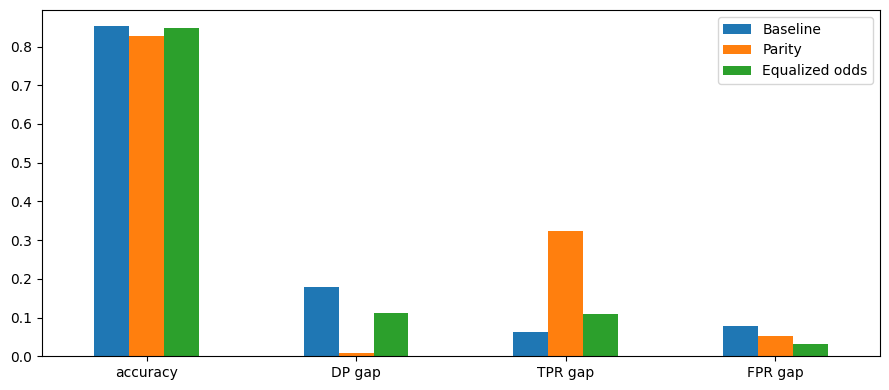

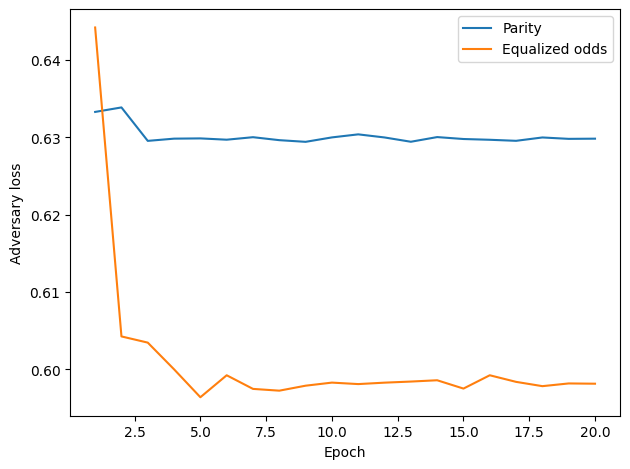

,epoch,parity,eq_odds
0,1,0.6333,0.6442
1,2,0.6338,0.6043
2,3,0.6295,0.6035
3,4,0.6298,0.6000
4,5,0.6298,0.5964
5,6,0.6297,0.5992
6,7,0.6300,0.5975
7,8,0.6296,0.5973
8,9,0.6294,0.5979
9,10,0.6300,0.5983


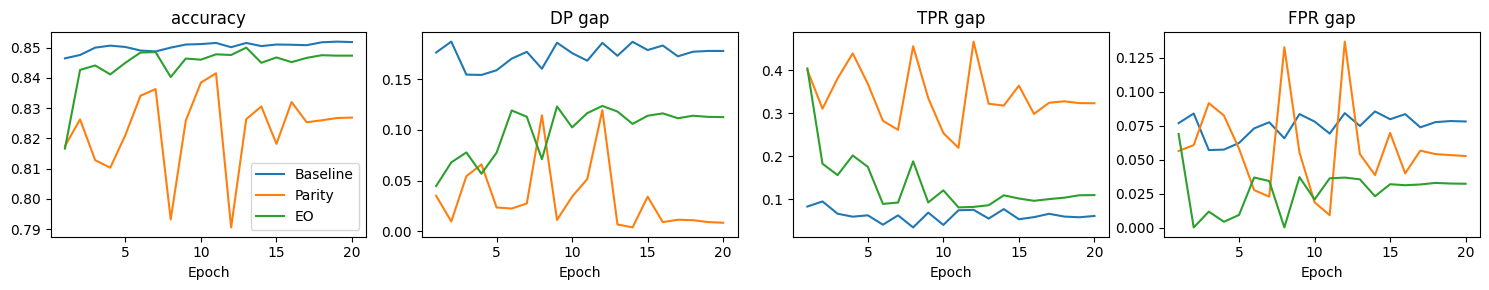

In [3]:
P_base,h_base = train(data,debias=False,epochs=EPOCHS)
P_dp,h_dp = train(data,mode='parity',epochs=EPOCHS)
P_eo,h_eo = train(data,mode='eq_odds',epochs=EPOCHS)
base_rows = {'Baseline':result(P_base),'Parity':result(P_dp),'Equalized odds':result(P_eo)}
base_table = show(base_rows,'baseline.csv')
base_table.T.plot.bar(rot=0,figsize=(9,4)); plt.tight_layout(); plt.savefig(OUT/'comparison.png'); plt.show()
for h,label in [(h_dp,'Parity'),(h_eo,'Equalized odds')]:
    plt.plot(h.epoch,h.loss_A,label=label)
plt.xlabel('Epoch'); plt.ylabel('Adversary loss'); plt.legend(); plt.tight_layout(); plt.savefig(OUT/'adversary_loss.png'); plt.show()
display(pd.DataFrame({'epoch':h_dp.epoch,'parity':h_dp.loss_A,'eq_odds':h_eo.loss_A}).round(4))
fig,axes=plt.subplots(1,4,figsize=(15,3))
for h,label in [(h_base,'Baseline'),(h_dp,'Parity'),(h_eo,'EO')]:
    for ax,m in zip(axes,metrics): ax.plot(h.epoch,h[m],label=label); ax.set_title(m); ax.set_xlabel('Epoch')
axes[0].legend(); plt.tight_layout(); plt.savefig(OUT/'curves.png'); plt.show()

## Q2 — Score histograms
Compare overlap, not just the gap at threshold 0.5. Reuse the initial models.

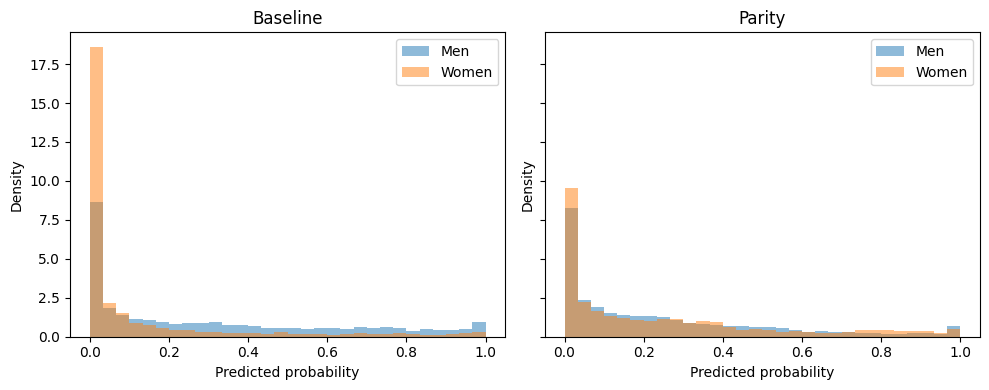

In [4]:
X,y_test,z_test=test(data)
z=z_test.numpy()
fig,axes=plt.subplots(1,2,figsize=(10,4),sharey=True)
for ax,P,label in zip(axes,[P_base,P_dp],['Baseline','Parity']):
    p=scores(P,X)
    for group,gname in [(1,'Men'),(0,'Women')]:
        ax.hist(p[z==group],bins=np.linspace(0,1,31),density=True,alpha=.5,label=gname)
    ax.set(title=label,xlabel='Predicted probability',ylabel='Density'); ax.legend()
plt.tight_layout(); plt.savefig(OUT/'scores.png'); plt.show()

## Q3 — DP versus TPR

In [5]:
rows=[]
for label,P in [('Baseline',P_base),('Parity',P_dp)]:
    pred=scores(P,X)>=.5; yy=y_test.numpy()
    for g,name in [(1,'Men'),(0,'Women')]:
        m=z==g
        rows.append({'model':label,'group':name,'base rate':yy[m].mean(),
                     'positive rate':pred[m].mean(),'TPR':pred[m&(yy==1)].mean(),'FPR':pred[m&(yy==0)].mean()})
display(pd.DataFrame(rows).round(4))

,model,group,base rate,positive rate,TPR,FPR
0,Baseline,Men,0.3100,0.2708,0.6400,0.1050
1,Baseline,Women,0.1195,0.0928,0.5784,0.0269
2,Parity,Men,0.3100,0.1697,0.4476,0.0449
3,Parity,Women,0.1195,0.1780,0.7713,0.0975


## Q4 — Can DP and EO both hold?
For group $z$, the selection rate is $TPR_z p_z + FPR_z(1-p_z)$, where $p_z=P(Y=1|Z=z)$. Under EO the two groups share TPR and FPR. DP then requires $(TPR-FPR)(p_1-p_0)=0$. With unequal base rates this means TPR = FPR: the binary decision has no discrimination between positive and negative labels. No new training is needed.

## Q5 — Proxy features

In [6]:
Xt,yt,zt=data['train_ds'].tensors
corr=pd.DataFrame(Xt.numpy(),columns=names).corrwith(pd.Series(zt.numpy()))
display(corr.reindex(corr.abs().sort_values(ascending=False).index).head(10).to_frame('correlation').round(4))

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,correlation
relationship_Husband,0.5842
marital-status_Married-civ-spouse,0.4473
relationship_Unmarried,-0.3273
relationship_Wife,-0.3099
occupation_Adm-clerical,-0.2783
marital-status_Divorced,-0.2360
hours-per-week,0.2290
occupation_Craft-repair,0.2285
marital-status_Widowed,-0.1855
marital-status_Never-married,-0.1843


## Small shared extension for Q6, Q7, Q9, Q10 and Q11

In [7]:
class Reverse(torch.autograd.Function):
    @staticmethod
    def forward(ctx,x,alpha):
        ctx.alpha=alpha
        return x.view_as(x)
    @staticmethod
    def backward(ctx,grad):
        return -ctx.alpha*grad,None

def train_extra(d, mode='parity', hidden=False, schedule=False, grl=False, representation=False, seed=42):
    set_seed(seed)
    P=Predictor(d['n_features']).to(d['device'])
    A=Adversary('parity' if mode=='eq_opp' else mode)
    if hidden:
        A.lin=nn.Sequential(nn.Linear(A.lin.in_features,16),nn.ReLU(),nn.Linear(16,1))
    if representation:
        A=nn.Sequential(nn.Linear(64,1),nn.Flatten(0))
    A=A.to(d['device'])
    opt_p=torch.optim.Adam(P.parameters(),lr=.001)
    opt_a=torch.optim.Adam(A.parameters(),lr=.01)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(opt_p,T_max=EPOCHS)
    loader=DataLoader(d['train_ds'],batch_size=128,shuffle=True)
    params=list(P.parameters()); history=[]; step=0
    def adversary_loss(v,y,z):
        mask=(y==1) if mode=='eq_opp' else torch.ones_like(y,dtype=torch.bool)
        if not mask.any(): return None
        logits=A(v[mask]) if representation else A(v[mask],y[mask])
        return F.binary_cross_entropy_with_logits(logits,z[mask])
    for epoch in range(1,EPOCHS+1):
        P.train(); A.train(); total_p=total_a=0.; count_a=0
        for x,y,z in loader:
            x,y,z=[v.to(d['device']) for v in (x,y,z)]
            step+=1
            alpha=np.sqrt(step/(EPOCHS*len(loader))) if schedule else 1.
            if representation:
                h=P.net[:-1](x); logits=P.net[-1](h).squeeze(-1); v=h
            else:
                logits=P(x); v=logits
            lp=F.binary_cross_entropy_with_logits(logits,y)
            opt_p.zero_grad(); opt_a.zero_grad()
            la=adversary_loss(Reverse.apply(v,alpha) if grl else v,y,z)
            if grl:
                (lp+la if la is not None else lp).backward()
                opt_p.step(); opt_a.step()
            else:
                if la is None:
                    lp.backward()
                else:
                    gp=torch.autograd.grad(lp,params,retain_graph=True)
                    ga=torch.autograd.grad(la,params,allow_unused=True)
                    for w,p,a in zip(params,gp,ga):
                        if a is None: w.grad=p
                        else:
                            u=a/(a.norm()+1e-8)
                            w.grad=p-(p*u).sum()*u-alpha*a
                opt_p.step()
                la_det=adversary_loss(v.detach(),y,z)
                if la_det is not None:
                    la_det.backward(); opt_a.step()
            total_p+=lp.item()*len(y)
            if la is not None:
                k=int((y==1).sum()) if mode=='eq_opp' else len(y)
                total_a+=la.item()*k; count_a+=k
        scheduler.step()
        row={'epoch':epoch,'loss_P':total_p/len(d['train_ds']), 'loss_A':total_a/max(count_a,1),'alpha':alpha,**result(P,d)}
        history.append(row)
        if epoch==1 or epoch%5==0: print({k:round(v,4) for k,v in row.items()})
    return P,pd.DataFrame(history)

def compare_curves(histories,filename):
    fig,axes=plt.subplots(1,2,figsize=(9,3))
    for label,h in histories.items():
        for ax,m in zip(axes,['loss_A','DP gap']):
            ax.plot(h.epoch,h[m],label=label); ax.set_title(m); ax.set_xlabel('Epoch')
    axes[0].legend(); plt.tight_layout(); plt.savefig(OUT/filename); plt.show()

## Q6 — Adversary with a hidden layer (2 new runs)

{'epoch': 1, 'loss_P': 0.4439, 'loss_A': 0.6307, 'alpha': 1.0, 'accuracy': np.float64(0.8249), 'DP gap': np.float64(0.0134), 'TPR gap': np.float64(0.3252), 'FPR gap': np.float64(0.0573)}
{'epoch': 5, 'loss_P': 0.3658, 'loss_A': 0.6297, 'alpha': 1.0, 'accuracy': np.float64(0.8307), 'DP gap': np.float64(0.0077), 'TPR gap': np.float64(0.2983), 'FPR gap': np.float64(0.0397)}
{'epoch': 10, 'loss_P': 0.3496, 'loss_A': 0.6292, 'alpha': 1.0, 'accuracy': np.float64(0.8221), 'DP gap': np.float64(0.0256), 'TPR gap': np.float64(0.3594), 'FPR gap': np.float64(0.0621)}
{'epoch': 15, 'loss_P': 0.3532, 'loss_A': 0.6298, 'alpha': 1.0, 'accuracy': np.float64(0.8313), 'DP gap': np.float64(0.0078), 'TPR gap': np.float64(0.3007), 'FPR gap': np.float64(0.0396)}
{'epoch': 20, 'loss_P': 0.3493, 'loss_A': 0.6297, 'alpha': 1.0, 'accuracy': np.float64(0.8305), 'DP gap': np.float64(0.0055), 'TPR gap': np.float64(0.3068), 'FPR gap': np.float64(0.0406)}
{'epoch': 1, 'loss_P': 0.4284, 'loss_A': 0.6312, 'alpha': 1.0,

,accuracy,DP gap,TPR gap,FPR gap
Linear (42),0.8269,0.0083,0.3237,0.0526
Hidden (42),0.8305,0.0055,0.3068,0.0406
Hidden (43),0.8301,0.0003,0.3171,0.0461


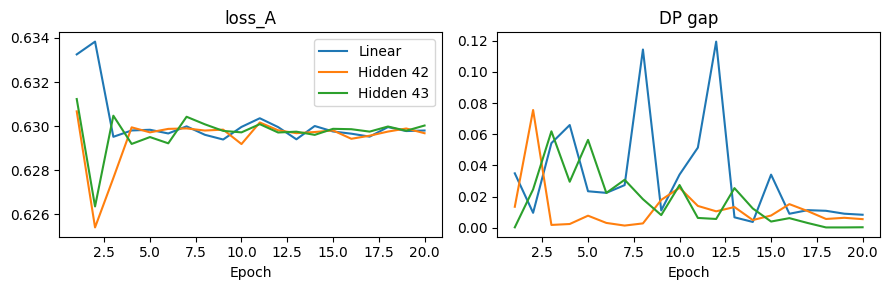

In [8]:
P_h1,h_h1=train_extra(data,hidden=True,seed=42)
P_h2,h_h2=train_extra(data,hidden=True,seed=43)
show({'Linear (42)':result(P_dp),'Hidden (42)':result(P_h1),'Hidden (43)':result(P_h2)},'q6.csv')
compare_curves({'Linear':h_dp,'Hidden 42':h_h1,'Hidden 43':h_h2},'q6_curves.png')

## Q7 — Square-root scheduling (1 new run)

{'epoch': 1, 'loss_P': 0.3952, 'loss_A': 0.631, 'alpha': np.float64(0.2236), 'accuracy': np.float64(0.8431), 'DP gap': np.float64(0.0984), 'TPR gap': np.float64(0.0642), 'FPR gap': np.float64(0.0238)}
{'epoch': 5, 'loss_P': 0.3644, 'loss_A': 0.6297, 'alpha': np.float64(0.5), 'accuracy': np.float64(0.8292), 'DP gap': np.float64(0.001), 'TPR gap': np.float64(0.3272), 'FPR gap': np.float64(0.0399)}
{'epoch': 10, 'loss_P': 0.3506, 'loss_A': 0.6293, 'alpha': np.float64(0.7071), 'accuracy': np.float64(0.8291), 'DP gap': np.float64(0.0046), 'TPR gap': np.float64(0.3068), 'FPR gap': np.float64(0.037)}
{'epoch': 15, 'loss_P': 0.3514, 'loss_A': 0.6299, 'alpha': np.float64(0.866), 'accuracy': np.float64(0.8239), 'DP gap': np.float64(0.0129), 'TPR gap': np.float64(0.3413), 'FPR gap': np.float64(0.0517)}
{'epoch': 20, 'loss_P': 0.3475, 'loss_A': 0.6298, 'alpha': np.float64(1.0), 'accuracy': np.float64(0.8272), 'DP gap': np.float64(0.0017), 'TPR gap': np.float64(0.3165), 'FPR gap': np.float64(0.0465

,accuracy,DP gap,TPR gap,FPR gap
Baseline,0.8518,0.1779,0.0615,0.0780
Fixed parity,0.8269,0.0083,0.3237,0.0526
Scheduled parity,0.8272,0.0017,0.3165,0.0465


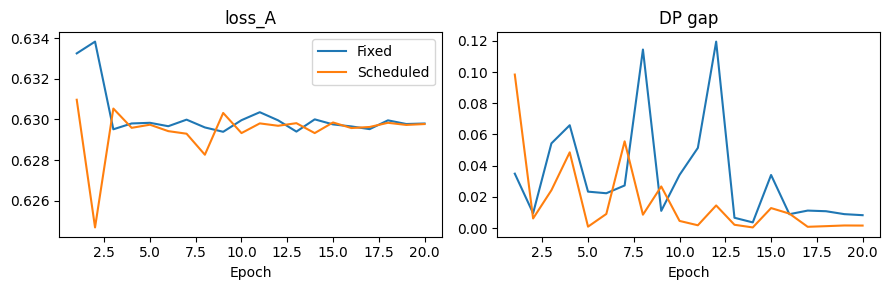

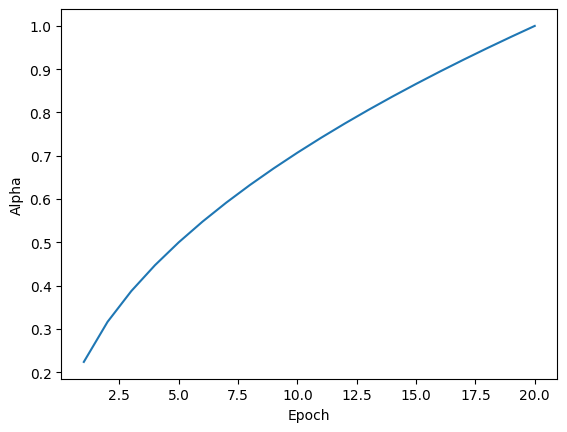

In [9]:
P_s,h_s=train_extra(data,schedule=True)
show({'Baseline':result(P_base),'Fixed parity':result(P_dp),'Scheduled parity':result(P_s)},'q7.csv')
compare_curves({'Fixed':h_dp,'Scheduled':h_s},'q7_curves.png')
plt.plot(h_s.epoch,h_s.alpha); plt.xlabel('Epoch'); plt.ylabel('Alpha'); plt.show()

## Q8 — Race (3 new runs)

In [10]:
race_data,_,race_names=prepare('race')
assert any(str(c).startswith('sex_') for c in race_names)
assert not any(str(c).startswith('race_') for c in race_names)
P_rb,h_rb=train(race_data,debias=False,epochs=EPOCHS)
P_rd,h_rd=train(race_data,mode='parity',epochs=EPOCHS)
P_re,h_re=train(race_data,mode='eq_odds',epochs=EPOCHS)
show({**{'Sex '+k:v for k,v in base_rows.items()},'Race Baseline':result(P_rb,race_data),'Race Parity':result(P_rd,race_data),'Race EO':result(P_re,race_data)},'q8.csv')

epoch   1 | L_P 0.3798 | L_A 0.0000 | acc 0.8440 | DP 0.099 | TPR 0.046 | FPR 0.041
epoch   5 | L_P 0.3073 | L_A 0.0000 | acc 0.8485 | DP 0.088 | TPR 0.023 | FPR 0.033
epoch  10 | L_P 0.2994 | L_A 0.0000 | acc 0.8497 | DP 0.079 | TPR 0.013 | FPR 0.027
epoch  15 | L_P 0.2935 | L_A 0.0000 | acc 0.8499 | DP 0.082 | TPR 0.018 | FPR 0.028
epoch  20 | L_P 0.2909 | L_A 0.0000 | acc 0.8497 | DP 0.085 | TPR 0.027 | FPR 0.029
epoch   1 | L_P 0.5393 | L_A 0.5619 | acc 0.8115 | DP 0.012 | TPR 0.075 | FPR 0.035
epoch   5 | L_P 0.3159 | L_A 0.4021 | acc 0.8431 | DP 0.035 | TPR 0.020 | FPR 0.013
epoch  10 | L_P 0.3061 | L_A 0.4016 | acc 0.8457 | DP 0.052 | TPR 0.024 | FPR 0.002
epoch  15 | L_P 0.2998 | L_A 0.4017 | acc 0.8469 | DP 0.053 | TPR 0.025 | FPR 0.001
epoch  20 | L_P 0.2974 | L_A 0.4018 | acc 0.8458 | DP 0.051 | TPR 0.027 | FPR 0.000
epoch   1 | L_P 0.3838 | L_A 0.4302 | acc 0.8445 | DP 0.088 | TPR 0.026 | FPR 0.031
epoch   5 | L_P 0.3099 | L_A 0.3982 | acc 0.8482 | DP 0.075 | TPR 0.023 | FP

,accuracy,DP gap,TPR gap,FPR gap
Sex Baseline,0.8518,0.1779,0.0615,0.0780
Sex Parity,0.8269,0.0083,0.3237,0.0526
Sex Equalized odds,0.8474,0.1126,0.1100,0.0322
Race Baseline,0.8497,0.0849,0.0268,0.0290
Race Parity,0.8458,0.0505,0.0266,0.0002
Race EO,0.8481,0.0726,0.0096,0.0178


,accuracy,DP gap,TPR gap,FPR gap
Sex Baseline,0.851846,0.177948,0.061508,0.078026
Sex Parity,0.826859,0.008305,0.323684,0.052615
Sex Equalized odds,0.847350,0.112615,0.109998,0.032216
Race Baseline,0.849709,0.084931,0.026806,0.029003
Race Parity,0.845802,0.050545,0.026568,0.000152
Race EO,0.848087,0.072629,0.009596,0.017795


## Q9 — Equal opportunity (1 new run)

In [11]:
P_opp,h_opp=train_extra(data,mode='eq_opp')
show({'Equalized odds':result(P_eo),'Equal opportunity':result(P_opp)},'q9.csv')

{'epoch': 1, 'loss_P': 0.4132, 'loss_A': 0.4732, 'alpha': 1.0, 'accuracy': np.float64(0.8362), 'DP gap': np.float64(0.049), 'TPR gap': np.float64(0.2162), 'FPR gap': np.float64(0.0)}
{'epoch': 5, 'loss_P': 0.3111, 'loss_A': 0.4071, 'alpha': 1.0, 'accuracy': np.float64(0.8482), 'DP gap': np.float64(0.1229), 'TPR gap': np.float64(0.0367), 'FPR gap': np.float64(0.0395)}
{'epoch': 10, 'loss_P': 0.3005, 'loss_A': 0.4065, 'alpha': 1.0, 'accuracy': np.float64(0.8502), 'DP gap': np.float64(0.161), 'TPR gap': np.float64(0.0195), 'FPR gap': np.float64(0.0677)}
{'epoch': 15, 'loss_P': 0.2946, 'loss_A': 0.4068, 'alpha': 1.0, 'accuracy': np.float64(0.8519), 'DP gap': np.float64(0.1534), 'TPR gap': np.float64(0.0094), 'FPR gap': np.float64(0.0618)}
{'epoch': 20, 'loss_P': 0.2917, 'loss_A': 0.4066, 'alpha': 1.0, 'accuracy': np.float64(0.8507), 'DP gap': np.float64(0.1574), 'TPR gap': np.float64(0.0012), 'FPR gap': np.float64(0.0656)}


,accuracy,DP gap,TPR gap,FPR gap
Equalized odds,0.8474,0.1126,0.1100,0.0322
Equal opportunity,0.8507,0.1574,0.0012,0.0656


,accuracy,DP gap,TPR gap,FPR gap
Equalized odds,0.847350,0.112615,0.109998,0.032216
Equal opportunity,0.850741,0.157354,0.001157,0.065648


## Q10 — Gradient reversal (1 new run)

{'epoch': 1, 'loss_P': 0.3893, 'loss_A': 0.6295, 'alpha': 1.0, 'accuracy': np.float64(0.8433), 'DP gap': np.float64(0.1038), 'TPR gap': np.float64(0.097), 'FPR gap': np.float64(0.031)}
{'epoch': 5, 'loss_P': 0.3223, 'loss_A': 0.6125, 'alpha': 1.0, 'accuracy': np.float64(0.8437), 'DP gap': np.float64(0.0725), 'TPR gap': np.float64(0.1866), 'FPR gap': np.float64(0.0048)}
{'epoch': 10, 'loss_P': 0.3126, 'loss_A': 0.6128, 'alpha': 1.0, 'accuracy': np.float64(0.8444), 'DP gap': np.float64(0.0805), 'TPR gap': np.float64(0.1654), 'FPR gap': np.float64(0.0119)}
{'epoch': 15, 'loss_P': 0.3068, 'loss_A': 0.6131, 'alpha': 1.0, 'accuracy': np.float64(0.8441), 'DP gap': np.float64(0.0815), 'TPR gap': np.float64(0.1766), 'FPR gap': np.float64(0.012)}
{'epoch': 20, 'loss_P': 0.3038, 'loss_A': 0.6124, 'alpha': 1.0, 'accuracy': np.float64(0.8445), 'DP gap': np.float64(0.0828), 'TPR gap': np.float64(0.1689), 'FPR gap': np.float64(0.0117)}


,accuracy,DP gap,TPR gap,FPR gap
Baseline,0.8518,0.1779,0.0615,0.0780
Projection parity,0.8269,0.0083,0.3237,0.0526
GRL parity,0.8445,0.0828,0.1689,0.0117


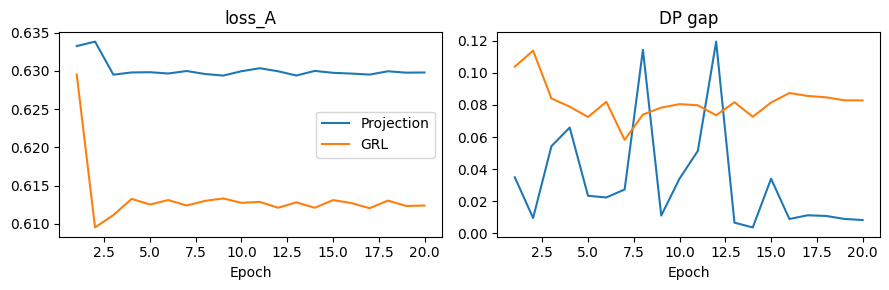

In [12]:
P_grl,h_grl=train_extra(data,grl=True)
show({'Baseline':result(P_base),'Projection parity':result(P_dp),'GRL parity':result(P_grl)},'q10.csv')
compare_curves({'Projection':h_dp,'GRL':h_grl},'q10_curves.png')

## Q11 — Hidden representation (1 new run)

{'epoch': 1, 'loss_P': 0.4266, 'loss_A': 0.6702, 'alpha': 1.0, 'accuracy': np.float64(0.8364), 'DP gap': np.float64(0.1083), 'TPR gap': np.float64(0.0514), 'FPR gap': np.float64(0.0335)}
{'epoch': 5, 'loss_P': 0.3352, 'loss_A': 0.6291, 'alpha': 1.0, 'accuracy': np.float64(0.8417), 'DP gap': np.float64(0.1266), 'TPR gap': np.float64(0.0902), 'FPR gap': np.float64(0.045)}
{'epoch': 10, 'loss_P': 0.3279, 'loss_A': 0.6188, 'alpha': 1.0, 'accuracy': np.float64(0.8423), 'DP gap': np.float64(0.0931), 'TPR gap': np.float64(0.1048), 'FPR gap': np.float64(0.022)}
{'epoch': 15, 'loss_P': 0.3244, 'loss_A': 0.6246, 'alpha': 1.0, 'accuracy': np.float64(0.8461), 'DP gap': np.float64(0.1177), 'TPR gap': np.float64(0.0848), 'FPR gap': np.float64(0.0371)}
{'epoch': 20, 'loss_P': 0.3258, 'loss_A': 0.5701, 'alpha': 1.0, 'accuracy': np.float64(0.8465), 'DP gap': np.float64(0.1183), 'TPR gap': np.float64(0.0896), 'FPR gap': np.float64(0.0378)}


,accuracy,DP gap,TPR gap,FPR gap
Scalar parity,0.8269,0.0083,0.3237,0.0526
Hidden representation,0.8465,0.1183,0.0896,0.0378


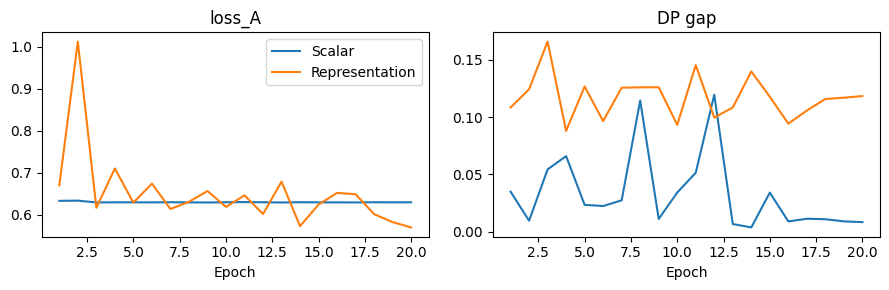

In [13]:
P_rep,h_rep=train_extra(data,representation=True)
show({'Scalar parity':result(P_dp),'Hidden representation':result(P_rep)},'q11.csv')
compare_curves({'Scalar':h_dp,'Representation':h_rep},'q11_curves.png')

## Q12 — Group thresholds

In [14]:
Xv,yv,zv=val
pv=scores(P_base,Xv); yv=yv.numpy(); zv=zv.numpy()
grid=np.linspace(0,1,101)
best=None
for tm in grid:
    for tf in grid:
        pred=pv>=np.where(zv==1,tm,tf)
        gap=abs(pred[zv==1].mean()-pred[zv==0].mean()); acc=(pred==yv).mean()
        key=(0,-acc,gap) if gap<=.01 else (1,gap,-acc)
        if best is None or key<best[0]: best=(key,tm,tf,gap,acc)
_,tm,tf,gap,acc=best
print(f'Validation: male threshold={tm:.2f}, female threshold={tf:.2f}, DP gap={gap:.4f}, accuracy={acc:.4f}')
Xt,yt,zt=test(data); pt=scores(P_base,Xt)
post=decision_metrics(pt>=np.where(zt.numpy()==1,tm,tf),yt.numpy(),zt.numpy())
show({'Baseline':result(P_base),'Adversarial parity':result(P_dp),'Threshold calibration':post},'q12.csv')

Validation: male threshold=0.69, female threshold=0.25, DP gap=0.0091, accuracy=0.8400


,accuracy,DP gap,TPR gap,FPR gap
Baseline,0.8518,0.1779,0.0615,0.0780
Adversarial parity,0.8269,0.0083,0.3237,0.0526
Threshold calibration,0.8337,0.0112,0.2976,0.0356


,accuracy,DP gap,TPR gap,FPR gap
Baseline,0.851846,0.177948,0.061508,0.078026
Adversarial parity,0.826859,0.008305,0.323684,0.052615
Threshold calibration,0.833714,0.011231,0.297596,0.035594


In [15]:
import shutil
archive_path=shutil.make_archive('/content/workshop_results','zip',OUT)
files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>